<a href="https://colab.research.google.com/github/Madhavi-1234/Machine-Learning-Practice/blob/main/US_accidents.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# US Accidents Exploratory Data Analysis


Analysing US traffic accident data to identify patterns and trends that may support accident prevention.

**Dataset Source:** Kaggle

In [ ]:
import kagglehub
import matplotlib.pyplot as plt
import seaborn as sns

path = kagglehub.dataset_download("sobhanmoosavi/us-accidents")

print("Dataset folder:", path)

Using Colab cache for faster access to the 'us-accidents' dataset.
Dataset folder: /kaggle/input/us-accidents


In [ ]:
from pathlib import Path

files = list(Path(path).rglob("*.csv"))

for file in files:
    print(file)

/kaggle/input/us-accidents/US_Accidents_March23.csv


In [ ]:
import pandas as pd

csv_path = files[0]

df = pd.read_csv(csv_path, nrows=5000)

print(df.shape)
display(df.head())

(5000, 46)


,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),...,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-1,Source2,3,2016-02-08 05:46:00,2016-02-08 11:00:00,39.865147,-84.058723,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Night,Night,Night
1,A-2,Source2,2,2016-02-08 06:07:59,2016-02-08 06:37:59,39.928059,-82.831184,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Night,Night,Day
2,A-3,Source2,2,2016-02-08 06:49:27,2016-02-08 07:19:27,39.063148,-84.032608,NaN,NaN,0.01,...,False,False,False,False,True,False,Night,Night,Day,Day
3,A-4,Source2,3,2016-02-08 07:23:34,2016-02-08 07:53:34,39.747753,-84.205582,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Day,Day,Day
4,A-5,Source2,2,2016-02-08 07:39:07,2016-02-08 08:09:07,39.627781,-84.188354,NaN,NaN,0.01,...,False,False,False,False,True,False,Day,Day,Day,Day


#Basic data quality questions

- Column ka meaning kya hai?
- Uska data type kya hai?
- Kitni values available hain?
- Kitni values missing hain?
- Missing percentage kitna hai?
- Kitni unique values hain?
- Kya koi invalid ya unusual values hain?
- Kya data mein extreme values/outliers hain?

In [ ]:
df.shape

(5000, 46)

In [ ]:
column_summary = pd.DataFrame({
    "Data_Type": df.dtypes,
    "Available_Values": df.count()
})

display(column_summary)

,Data_Type,Available_Values
ID,object,5000
Source,object,5000
Severity,int64,5000
Start_Time,object,5000
End_Time,object,5000
Start_Lat,float64,5000
Start_Lng,float64,5000
End_Lat,float64,0
End_Lng,float64,0
Distance(mi),float64,5000


In [ ]:
df.isnull().sum()

,0
ID,0
Source,0
Severity,0
Start_Time,0
End_Time,0
Start_Lat,0
Start_Lng,0
End_Lat,5000
End_Lng,5000
Distance(mi),0


In [ ]:
df.isnull().sum().sum()

np.int64(19987)

In [ ]:
Missing_Percentage= df.isnull().mean() * 100
Missing_Percentage

,0
ID,0.00
Source,0.00
Severity,0.00
Start_Time,0.00
End_Time,0.00
Start_Lat,0.00
Start_Lng,0.00
End_Lat,100.00
End_Lng,100.00
Distance(mi),0.00


In [ ]:
df.columns

Index(['ID', 'Source', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat',
       'Start_Lng', 'End_Lat', 'End_Lng', 'Distance(mi)', 'Description',
       'Street', 'City', 'County', 'State', 'Zipcode', 'Country', 'Timezone',
       'Airport_Code', 'Weather_Timestamp', 'Temperature(F)', 'Wind_Chill(F)',
       'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction',
       'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition', 'Amenity',
       'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway',
       'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal',
       'Turning_Loop', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight',
       'Astronomical_Twilight'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 46 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ID                     5000 non-null   object 
 1   Source                 5000 non-null   object 
 2   Severity               5000 non-null   int64  
 3   Start_Time             5000 non-null   object 
 4   End_Time               5000 non-null   object 
 5   Start_Lat              5000 non-null   float64
 6   Start_Lng              5000 non-null   float64
 7   End_Lat                0 non-null      float64
 8   End_Lng                0 non-null      float64
 9   Distance(mi)           5000 non-null   float64
 10  Description            5000 non-null   object 
 11  Street                 5000 non-null   object 
 12  City                   5000 non-null   object 
 13  County                 5000 non-null   object 
 14  State                  5000 non-null   object 
 15  Zipc

In [ ]:
df.count()

,0
ID,5000
Source,5000
Severity,5000
Start_Time,5000
End_Time,5000
Start_Lat,5000
Start_Lng,5000
End_Lat,0
End_Lng,0
Distance(mi),5000


In [ ]:
df.nunique()

,0
ID,5000
Source,2
Severity,4
Start_Time,4910
End_Time,4929
Start_Lat,3622
Start_Lng,3591
End_Lat,0
End_Lng,0
Distance(mi),14


In [ ]:
cols = [
    "Start_Lat",
    "Start_Lng",
    "End_Lat",
    "End_Lng",
    "Wind_Chill(F)",
    "Precipitation(in)",
    "Wind_Speed(mph)"
]

display(df[cols].isnull().sum())

,0
Start_Lat,0
Start_Lng,0
End_Lat,5000
End_Lng,5000
Wind_Chill(F),4540
Precipitation(in),4808
Wind_Speed(mph),459


In [ ]:
df["Source"].value_counts(dropna=False)

,count
Source,
Source2,4984
Source3,16


In [ ]:
pd.crosstab(
    df["Source"],
    df["End_Lat"].isnull()
)

End_Lat,True
Source,
Source2,4984
Source3,16


In [ ]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,5000,5000,A-5000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Source,5000,2,Source2,4984,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Severity,5000.0,NaN,NaN,NaN,2.4118,0.495853,1.0,2.0,2.0,3.0,4.0
Start_Time,5000,4910,2016-06-26 08:16:07,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
End_Time,5000,4929,2016-07-16 16:50:00,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Start_Lat,5000.0,NaN,NaN,NaN,38.277176,0.873445,36.401604,37.695385,38.027338,38.64341,41.428753
Start_Lng,5000.0,NaN,NaN,NaN,-116.241672,13.51452,-123.793976,-122.107246,-121.723686,-121.271286,-81.550728
End_Lat,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
End_Lng,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Distance(mi),5000.0,NaN,NaN,NaN,0.00687,0.129207,0.0,0.0,0.0,0.0,7.07


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df["ID"].duplicated().sum()

np.int64(0)

In [ ]:
df["Severity"].value_counts(dropna=False)

,count
Severity,
2,2938
3,2053
4,5
1,4


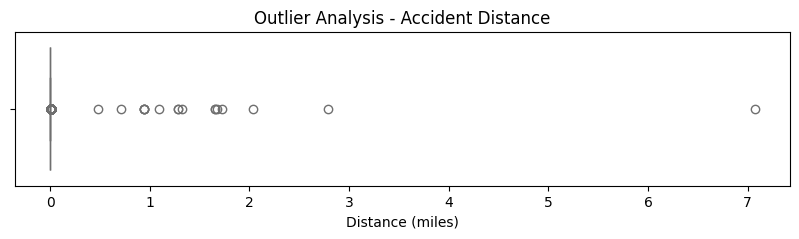

In [ ]:
plt.figure(figsize=(10, 2))

sns.boxplot(
    x=df["Distance(mi)"],
    color="skyblue"
)

plt.title("Outlier Analysis - Accident Distance")
plt.xlabel("Distance (miles)")
plt.show()

In [ ]:
dist = df["Distance(mi)"].dropna()

Q1 = dist.quantile(0.25)
Q3 = dist.quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

potential_outliers = df[
    df["Distance(mi)"] > upper_bound
]

print("Upper Bound:", upper_bound)
print("Potential Outlier Count:", len(potential_outliers))

display(
    potential_outliers[
        ["ID", "Distance(mi)", "State", "City"]
    ]
)

Upper Bound: 0.0
Potential Outlier Count: 600


,ID,Distance(mi),State,City
0,A-1,0.01,OH,Dayton
1,A-2,0.01,OH,Reynoldsburg
2,A-3,0.01,OH,Williamsburg
3,A-4,0.01,OH,Dayton
4,A-5,0.01,OH,Dayton
...,...,...,...,...
723,A-724,0.01,OH,Dayton
724,A-725,0.01,OH,Dayton
725,A-726,0.01,OH,Westerville
726,A-727,0.01,OH,Akron


In [ ]:
dist = df["Distance(mi)"].dropna()

print("Total values:", len(dist))
print("Zero values:", (dist == 0).sum())
print("Non-zero values:", (dist > 0).sum())
print("Minimum:", dist.min())
print("Maximum:", dist.max())

print("\nDistribution:")
print(dist.describe())

Total values: 5000
Zero values: 4400
Non-zero values: 600
Minimum: 0.0
Maximum: 7.07

Distribution:
count    5000.000000
mean        0.006870
std         0.129207
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         7.070000
Name: Distance(mi), dtype: float64


In [ ]:
positive_dist = df.loc[
    df["Distance(mi)"] > 0,
    "Distance(mi)"
]

positive_dist.describe()

,Distance(mi)
count,600.000000
mean,0.057250
std,0.369373
min,0.010000
25%,0.010000
50%,0.010000
75%,0.010000
max,7.070000


In [ ]:
positive_dist.value_counts().head(10)


,count
Distance(mi),
0.01,583
0.94,4
1.28,2
1.65,2
1.32,1
0.48,1
1.09,1
2.79,1
1.67,1


In [ ]:
print("Exactly 0.01:", (positive_dist == 0.01).sum())
print("Greater than 0.01:", (positive_dist > 0.01).sum())

Exactly 0.01: 583
Greater than 0.01: 17


In [ ]:
distance_analysis = df.groupby("Source").agg(
    Total_Records=("Distance(mi)", "size"),

    Zero_Count=("Distance(mi)",
                lambda x: (x == 0).sum()),

    Point_001_Count=("Distance(mi)",
                     lambda x: (x == 0.01).sum()),

    Greater_001=("Distance(mi)",
                 lambda x: (x > 0.01).sum())
)

display(distance_analysis)

,Total_Records,Zero_Count,Point_001_Count,Greater_001
Source,,,,
Source2,4984,4398,571,15
Source3,16,2,12,2


### Distance(mi) — Data Quality and Outlier Investigation

- The dataset contains 5,000 accident records.
- 4,400 records (88%) have a distance value of 0 miles.
- 600 records (12%) have non-zero distance values.
- Among the non-zero records, 583 (97.17%) have a value of exactly 0.01 miles, while only 17 (2.83%) have values greater than 0.01 miles.
- The first quartile, median, and third quartile are all 0 for the complete dataset, resulting in an IQR of 0.
- Even after excluding zero values, the three quartiles remain 0.01, resulting in another IQR of 0.
- Therefore, the conventional IQR method does not effectively distinguish unusual observations in this highly concentrated distribution.

**Conclusion:** The Distance feature requires further investigation before making any data-removal or transformation decisions. Its original values will be preserved for now. During feature engineering, we can evaluate zero-value indicators, missing-value indicators, and possible transformations based on their usefulness for the prediction task.

In [ ]:
df["Temperature(F)"].describe()

,Temperature(F)
count,4978.000000
mean,69.849900
std,18.308741
min,3.900000
25%,60.800000
50%,71.100000
75%,82.400000
max,106.000000


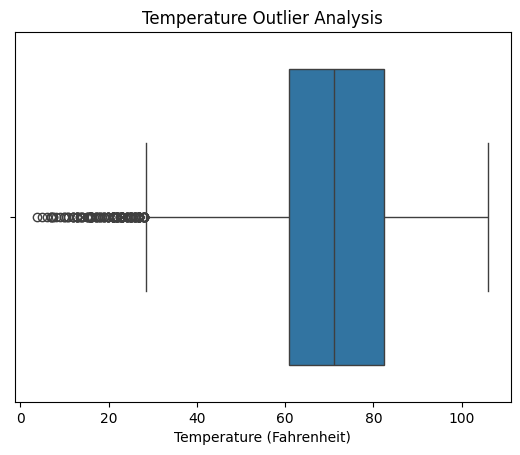

In [ ]:
sns.boxplot(x=df["Temperature(F)"])
plt.title("Temperature Outlier Analysis")
plt.xlabel("Temperature (Fahrenheit)")
plt.show()

In [ ]:
df.columns


Index(['ID', 'Source', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat',
       'Start_Lng', 'End_Lat', 'End_Lng', 'Distance(mi)', 'Description',
       'Street', 'City', 'County', 'State', 'Zipcode', 'Country', 'Timezone',
       'Airport_Code', 'Weather_Timestamp', 'Temperature(F)', 'Wind_Chill(F)',
       'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction',
       'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition', 'Amenity',
       'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway',
       'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal',
       'Turning_Loop', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight',
       'Astronomical_Twilight'],
      dtype='object')

In [ ]:
df['Wind_Speed(mph)'].describe()

,Wind_Speed(mph)
count,4541.000000
mean,9.396477
std,4.310576
min,1.200000
25%,5.800000
50%,9.200000
75%,11.500000
max,31.100000


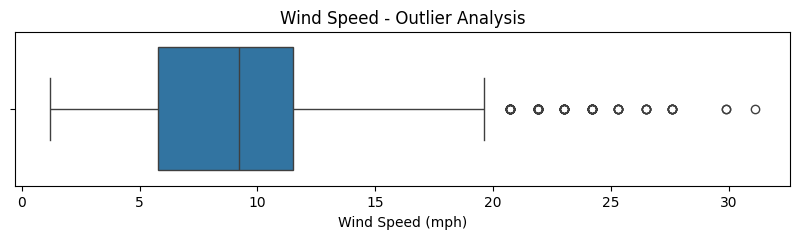

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 2))

sns.boxplot(x=df["Wind_Speed(mph)"])

plt.title("Wind Speed - Outlier Analysis")
plt.xlabel("Wind Speed (mph)")
plt.show()

In [ ]:
col = df["Wind_Speed(mph)"].dropna()

Q1 = col.quantile(0.25)
Q3 = col.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = col[
    (col < lower_bound) | (col > upper_bound)
]

print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Potential Outliers:", len(outliers))

IQR: 5.7
Lower Bound: -2.750000000000001
Upper Bound: 20.05
Potential Outliers: 89


In [ ]:
wind_outliers = df[df["Wind_Speed(mph)"] > upper_bound]

display(
    wind_outliers[[ "ID","Wind_Speed(mph)","Weather_Condition", "Temperature(F)","Visibility(mi)","State","City"]].sort_values( by="Wind_Speed(mph)", ascending=False ).head(15)
)

,ID,Wind_Speed(mph),Weather_Condition,Temperature(F),Visibility(mi),State,City
687,A-688,31.1,Scattered Clouds,59.0,10.0,OH,North Olmsted
294,A-295,29.9,Clear,59.4,10.0,OH,Dayton
293,A-294,29.9,Clear,59.4,10.0,OH,Dayton
287,A-288,27.6,Overcast,48.0,10.0,OH,Dayton
292,A-293,27.6,Scattered Clouds,57.0,10.0,OH,Dayton
2728,A-2729,27.6,Partly Cloudy,64.9,10.0,CA,Sausalito
3705,A-3706,27.6,Clear,75.2,10.0,CA,Rio Vista
1260,A-1261,27.6,Partly Cloudy,70.0,10.0,CA,San Francisco
291,A-292,27.6,Scattered Clouds,57.0,10.0,OH,Dayton
1939,A-1940,26.5,Clear,76.8,10.0,CA,Fairfield


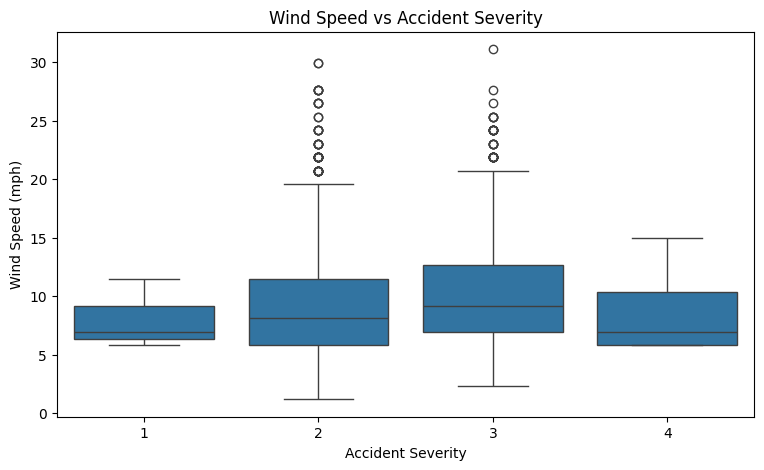

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Severity",
    y="Wind_Speed(mph)"
)

plt.title("Wind Speed vs Accident Severity")
plt.xlabel("Accident Severity")
plt.ylabel("Wind Speed (mph)")
plt.show()

In [ ]:
wind_severity = df.groupby("Severity")["Wind_Speed(mph)"].agg(
    ["count", "mean", "median", "std"]
).round(2)

display(wind_severity)

,count,mean,median,std
Severity,,,,
1,3,8.07,6.9,3.02
2,2628,9.08,8.1,4.23
3,1905,9.83,9.2,4.38
4,5,8.78,6.9,3.96


## Wind Speed vs Accident Severity

The wind-speed distributions across Severity categories appear relatively similar, with no clear increasing trend in average wind speed as severity increases.

Severity 3 has the highest mean wind speed (9.83 mph), while Severity 4 has a mean of 8.78 mph. However, the number of valid observations for Severity 1 and Severity 4 is very small.

**Conclusion:** No strong visual or descriptive relationship is evident in the analysed sample. Wind Speed will be retained as a potential feature for further model evaluation rather than removed based on this analysis alone.

In [ ]:
df["Visibility(mi)"].describe()

,Visibility(mi)
count,4958.000000
mean,9.465611
std,1.886629
min,0.200000
25%,10.000000
50%,10.000000
75%,10.000000
max,40.000000


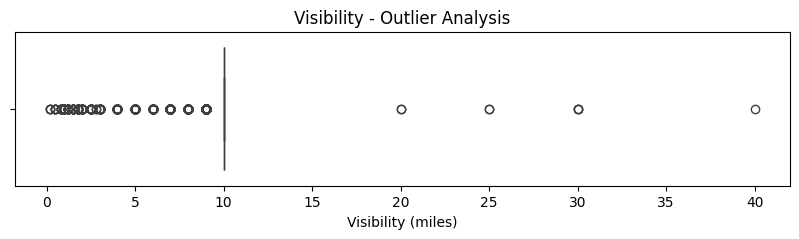

In [ ]:
plt.figure(figsize=(10, 2))

sns.boxplot( x=df["Visibility(mi)"])

plt.title("Visibility - Outlier Analysis")
plt.xlabel("Visibility (miles)")
plt.show()

In [ ]:
visiblity_severity = df.groupby("Severity")['Visibility(mi)'].agg(
    ["count", "mean", "median", "std"]
).round(2)

display(visiblity_severity)

,count,mean,median,std
Severity,,,,
1,4,8.50,8.5,1.73
2,2900,9.40,10.0,1.91
3,2049,9.56,10.0,1.85
4,5,9.20,10.0,1.79


In [ ]:
high_visibility = df[
    df["Visibility(mi)"] > 10
]

display(
    high_visibility[
        [
            "Visibility(mi)",
            "Weather_Condition",
            "Airport_Code",
            "Source",
            "Weather_Timestamp"
        ]
    ].sort_values(
        "Visibility(mi)",
        ascending=False
    ).head(10)
)

,Visibility(mi),Weather_Condition,Airport_Code,Source,Weather_Timestamp
2903,40.0,Clear,KCIC,Source2,2016-07-13 10:47:00
764,30.0,Clear,KPAO,Source2,2016-06-21 12:47:00
794,30.0,Clear,KPAO,Source2,2016-06-21 15:47:00
777,30.0,Clear,KPAO,Source2,2016-06-21 13:47:00
2244,25.0,Partly Cloudy,KCIC,Source2,2016-07-06 10:50:00
3028,25.0,Clear,KCIC,Source2,2016-07-14 13:47:00
2803,20.0,Clear,KPAO,Source2,2016-07-12 11:47:00
2797,20.0,Clear,KPAO,Source2,2016-07-12 11:47:00


In [ ]:
high_visibility["Visibility(mi)"].value_counts().sort_index()

,count
Visibility(mi),
20.0,2
25.0,2
30.0,3
40.0,1


In [ ]:
print("Total high visibility records:", len(high_visibility))
print("Unique high visibility values:",
      high_visibility["Visibility(mi)"].nunique())

print("Total records >= 40:",
      (df["Visibility(mi)"] >= 40).sum())

Total high visibility records: 8
Unique high visibility values: 4
Total records >= 40: 1


## Visibility vs Accident Severity

The mean visibility values across Severity categories are relatively similar. Severity 2 and Severity 3 have median visibility values of 10 miles.

No substantial difference is apparent between the two major severity groups based on the descriptive statistics. However, Severity 1 and Severity 4 have very small sample sizes, so their results should be interpreted cautiously.

**Conclusion:** No strong relationship is evident from this initial descriptive comparison. Visibility will be retained for further investigation and model evaluation.

In [ ]:
df["Humidity(%)"].describe()

,Humidity(%)
count,4978.000000
mean,51.823423
std,23.819417
min,8.000000
25%,32.000000
50%,51.000000
75%,70.000000
max,100.000000


In [ ]:
wind_outliers["Weather_Timestamp"].value_counts(
    dropna=False
).head(10)

,count
Weather_Timestamp,
2016-02-12 19:53:00,2
2016-02-19 14:53:00,2
2016-02-19 15:58:00,2
2016-02-19 11:56:00,2
2016-02-19 11:58:00,2
2016-06-24 01:56:00,2
2016-07-03 14:54:00,2
2016-07-30 15:58:00,2
2016-07-16 20:58:00,2


In [ ]:
wind_outliers["Airport_Code"].value_counts(
    dropna=False
).head(10)


NameError: name 'wind_outliers' is not defined